In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
pd.set_option('display.max_rows', 500)
%matplotlib inline

In [5]:

df = pd.read_csv(r"C:\Users\rupes\OneDrive\Documents\GitHub\lab-eda-univariate\data\amz_uk_price_prediction_dataset.csv")

In [6]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [ ]:
### Part 1: Understanding Product Categories
#1. **Frequency Tables**:
    # Generate a frequency table for the product `category`.

In [10]:
frequency_table = df['category'].value_counts()

# Calculating the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True)

frequency_table, proportion_table

(category
 Sports & Outdoors                                   836265
 Beauty                                               19312
 Handmade Clothing, Shoes & Accessories               19229
 Bath & Body                                          19092
 Birthday Gifts                                       18978
 Manicure & Pedicure Products                         18940
 Skin Care                                            18769
 Make-up                                              18756
 Hair Care                                            18735
 Fragrances                                           18564
 Handmade Gifts                                       18295
 Handmade Home Décor                                  18146
 Luggage and travel gear                              18142
 Handmade Jewellery                                   18044
 Handmade Artwork                                     17878
 Women                                                17772
 Handmade Home & Kitchen Produ

In [12]:
df.select_dtypes("number").columns ## Extracting column names with numerical data types from the dataframe

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [18]:
df.select_dtypes("number").nunique().sort_values(ascending=False) ## Counting and sorting the unique values for each numerical column in descending order

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [ ]:
#### discussed in class #Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.

In [24]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical 

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [27]:
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)
df_categorical

,asin,title,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,Hi-Fi Speakers
...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,Motorbike Clothing


In [32]:
#creating a crosstab
my_table = pd.crosstab(index = df_categorical["category"],  # Make a crosstab
                              columns="count")      # Name the count column
my_table.head(20)

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
Agricultural Equipment & Supplies,8530
Alexa Built-In Devices,107
Art & Craft Supplies,258
Arts & Crafts,9549


In [35]:
# Sort the crosstab in descending order based on the count and select the top 5
top_5_categories = my_table.sort_values(by="count", ascending=False).head(5)
print(top_5_categories)

col_0                                    count
category                                      
Sports & Outdoors                       836265
Beauty                                   19312
Handmade Clothing, Shoes & Accessories   19229
Bath & Body                              19092
Birthday Gifts                           18978


In [33]:
(my_table/my_table.sum()).round(2)

col_0,count
category,
3D Printers,0.00
3D Printing & Scanning,0.00
Abrasive & Finishing Products,0.00
Action Cameras,0.00
Adapters,0.00
Agricultural Equipment & Supplies,0.00
Alexa Built-In Devices,0.00
Art & Craft Supplies,0.00
Arts & Crafts,0.00


In [ ]:
#2. **Visualizations**:
    #- Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
   # - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [47]:
top_10_categories = my_table.sort_values(by="count", ascending=False).head(10)
print(top_10_categories)

col_0                                    count
category                                      
Sports & Outdoors                       836265
Beauty                                   19312
Handmade Clothing, Shoes & Accessories   19229
Bath & Body                              19092
Birthday Gifts                           18978
Manicure & Pedicure Products             18940
Skin Care                                18769
Make-up                                  18756
Hair Care                                18735
Fragrances                               18564


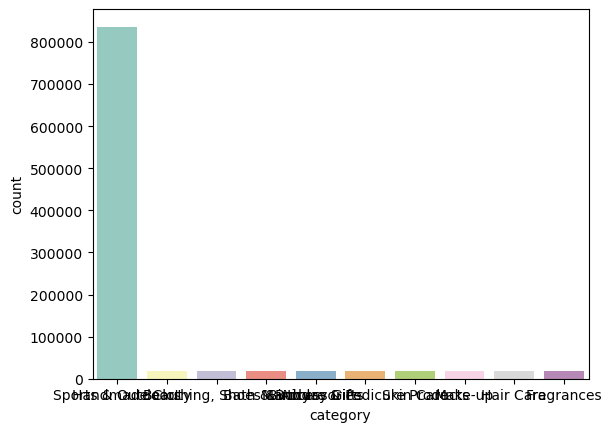

In [52]:
#sns.barplot(x=top_10_categories .index, y=category .values, palette="Set3");
sns.barplot(x=top_10_categories.index, y=top_10_categories["count"], palette="Set3");

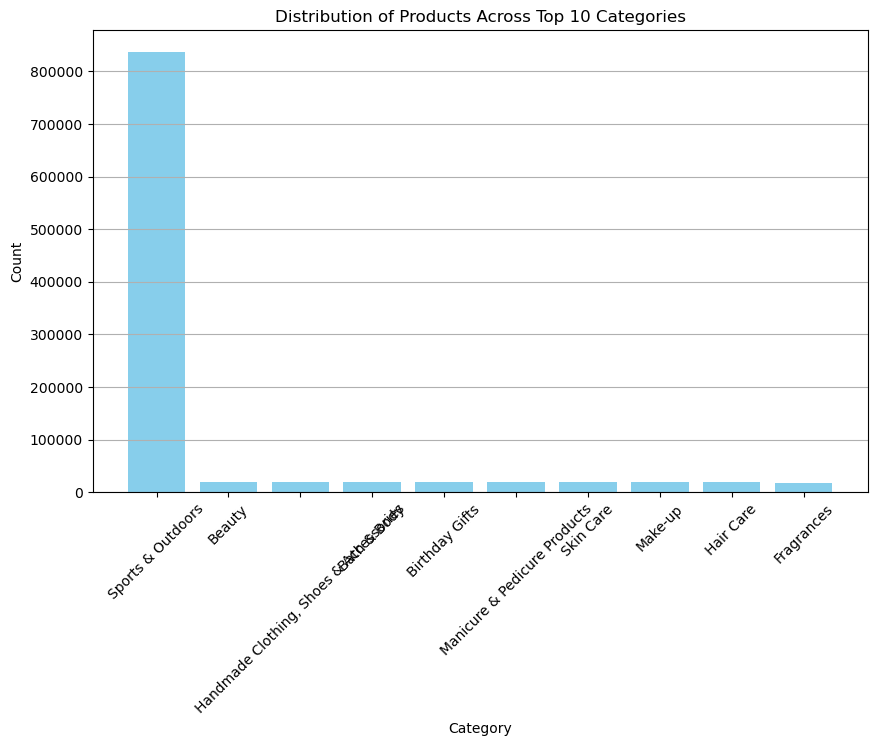

In [51]:
plt.figure(figsize=(10, 6))
plt.bar(top_10_categories.index, top_10_categories['count'], color='skyblue')
plt.title('Distribution of Products Across Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y')

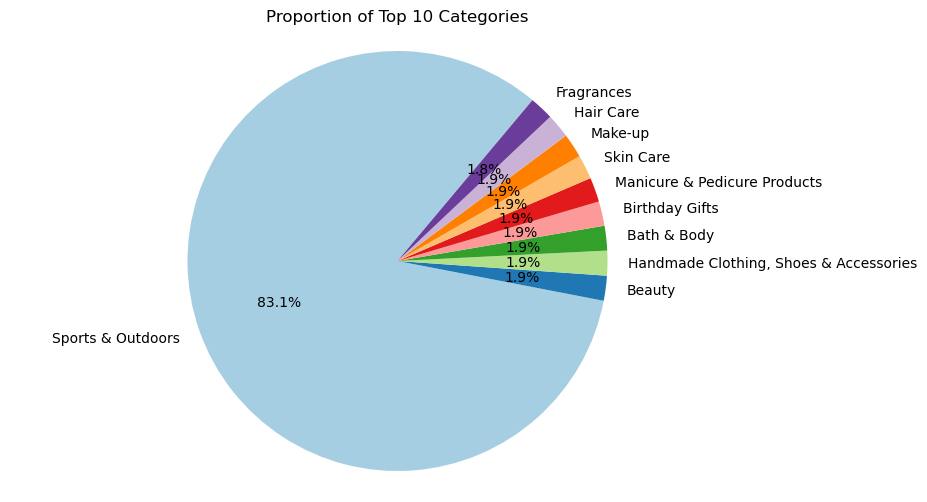

In [72]:
plt.figure(figsize=(10, 6))
plt.pie(top_10_categories['count'], labels=top_10_categories.index, autopct='%1.1f%%', startangle=50, colors=plt.cm.Paired.colors)
plt.title('Proportion of Top 10 Categories')
plt.axis('equal')  # Equal aspect ratio ensures the pie is drawn as a circle.
plt.show()

In [ ]:
### Part 2: Delving into Product Pricing
#1. **Measures of Centrality**:
   # - Calculate the mean, median, and mode for the `price` of products.
    #- What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [78]:
df["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

Measures of Centrality

In [56]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(89.24380943923663, 19.09, 9.99)

In [57]:
#Measures of Dispersion

variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.48532256528,
 345.60886175352226,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [60]:
df['price'].quantile(0.75) #75% product price below 45.99

45.99

In [ ]:
sns.histplot(df.cut['price'], kde=True, bins=10, color="salmon")

In [83]:
df["price_quantile"]=pd.qcut(df.["price"],q=4)
df.price_quantile.value_counts()

SyntaxError: invalid syntax (2688749581.py, line 1)

C:\Users\rupes\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='price', ylabel='Count'>

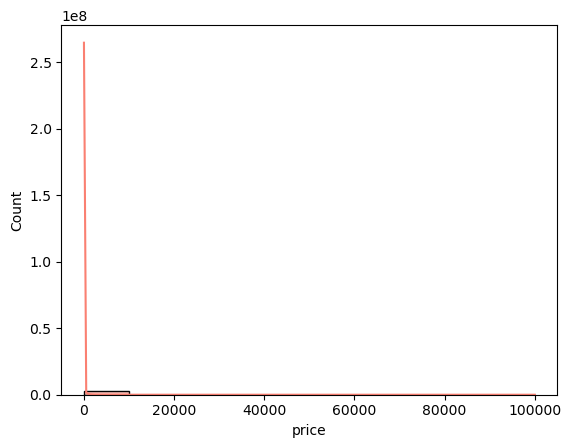

In [65]:
sns.histplot(df['price'], kde=True, bins=10, color="salmon")

In [ ]:
sns.countplots

<Axes: >

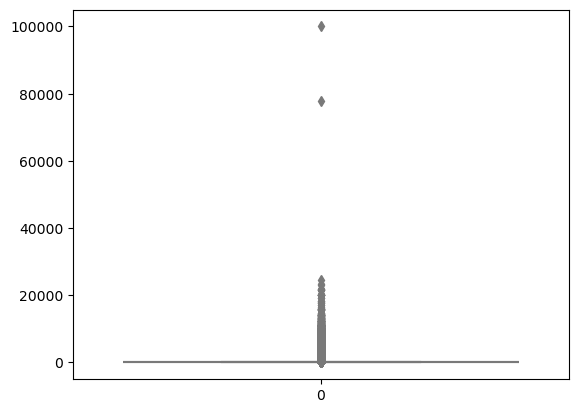

In [62]:
sns.boxplot(data = df['price'], color="lightblue")

In [ ]:
### Part 3: Unpacking Product Ratings

#**Measures of Centrality**:
   # - Calculate the mean, median, and mode for the `rating` of products.
   # - How do customers generally rate products? Is there a common trend?

In [68]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

mean_rating, median_rating, mode_rating

(2.152836472966065, 0.0, 0.0)

In [88]:
df["stars"] = df["stars"].loc[df["stars"] != 0]

In [89]:
#Measures of Dispersion

variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating= df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_price - min_rating
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, min_rating, max_rating, range_rating, quantiles_rating

(0.3083433752380519,
 0.5552867504614637,
 1.0,
 5.0,
 99999.0,
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64)

In [92]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(-2.379568112212788, 9.78193769066431)

In [86]:
df["stars"] = df["stars"].loc[df["stars"] ! = 0]

SyntaxError: invalid syntax (2296500084.py, line 1)

C:\Users\rupes\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


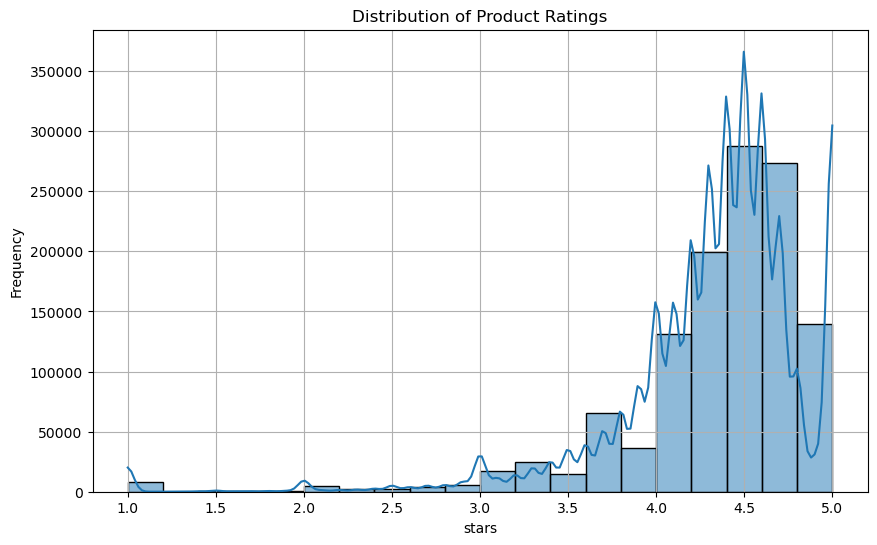

The most common rating is: 4.5


In [91]:
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=20, kde=True)
plt.title('Distribution of Product Ratings')
plt.xlabel('stars')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Checking the most common rating
most_common_rating = df['stars'].mode()[0]
print(f"The most common rating is: {most_common_rating}")